In [ ]:
# IMPORTANT: SOME KAGGLE DATA SOURCES ARE PRIVATE
# RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES.
import kagglehub
kagglehub.login()


Kaggle credentials set.
Kaggle credentials successfully validated.


In [ ]:
mariaspasyuk_simpsons_path = kagglehub.dataset_download('mariaspasyuk/simpsons')
print('Data source import complete.')


100%|██████████| 486M/486M [00:04<00:00, 107MB/s]

Extracting files...


Data source import complete.


Импортируем необходимые библиотеки.

In [ ]:
import os
import torch
import glob
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torch.nn as nn
from transformers import AutoImageProcessor, AutoModelForImageClassification, TrainingArguments, Trainer
from datasets import Dataset as HFDataset
import numpy as np
from sklearn.metrics import accuracy_score, classification_report
from collections import defaultdict
import wandb
import random
from tqdm import tqdm, tqdm_notebook
from torch.utils.data import Subset
import warnings
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns
import pandas as pd

np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"{device=}")

device=device(type='cuda')


In [ ]:
class SimpsonsTestDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.image_files = [f for f in os.listdir(root_dir) if f.endswith(('.jpg', '.jpeg'))]
        self.classes = sorted(list(set([self._get_class_name(f) for f in self.image_files])))
        self.class_to_idx = {cls: idx for idx, cls in enumerate(self.classes)}

    def _get_class_name(self, filename):
        return '_'.join(filename.rsplit('.', 1)[0].split('_')[:-1])

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_name = self.image_files[idx]
        img_path = os.path.join(self.root_dir, img_name)
        image = Image.open(img_path).convert('RGB')

        class_name = self._get_class_name(img_name)
        label = self.class_to_idx[class_name]

        return image, label

In [ ]:
from torchvision import datasets
test_dataset = SimpsonsTestDataset(root_dir="/root/.cache/kagglehub/datasets/mariaspasyuk/simpsons/versions/1/test_dataset")
test_dataset.classes = [label.replace('_', ' ') for label in test_dataset.classes]

In [ ]:
from transformers import Qwen3VLForConditionalGeneration, AutoProcessor

model_qwen = Qwen3VLForConditionalGeneration.from_pretrained("Qwen/Qwen3-VL-2B-Instruct", dtype="auto", device_map="auto")
processor_qwen = AutoProcessor.from_pretrained("Qwen/Qwen3-VL-2B-Instruct")
model_qwen.eval()

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/4.26G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

...

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

chat_template.json: 0.00B [00:00, ?B/s]

Qwen3VLForConditionalGeneration(
  (model): Qwen3VLModel(
    (visual): Qwen3VLVisionModel(
      (patch_embed): Qwen3VLVisionPatchEmbed(
        (proj): Conv3d(3, 1024, kernel_size=(2, 16, 16), stride=(2, 16, 16))
      )
      (pos_embed): Embedding(2304, 1024)
      (rotary_pos_emb): Qwen3VLVisionRotaryEmbedding()
      (blocks): ModuleList(
        (0-23): 24 x Qwen3VLVisionBlock(
          (norm1): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
          (norm2): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
          (attn): Qwen3VLVisionAttention(
            (qkv): Linear(in_features=1024, out_features=3072, bias=True)
            (proj): Linear(in_features=1024, out_features=1024, bias=True)
          )
          (mlp): Qwen3VLVisionMLP(
            (linear_fc1): Linear(in_features=1024, out_features=4096, bias=True)
            (linear_fc2): Linear(in_features=4096, out_features=1024, bias=True)
            (act_fn): GELUTanh()
          )
        )
      )
 

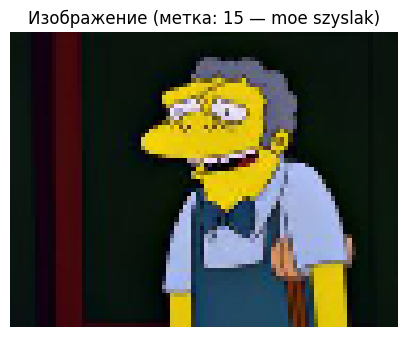

In [ ]:
image, label = test_dataset[170]
plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.axis('off')
plt.title(f"Изображение (метка: {label} — {test_dataset.classes[label]})")
plt.show()

In [ ]:
prompt1 = """Answer, what simpsons' character from list is on the picture. The list to choose character:
          abraham grampa simpson, apu nahasapeemapetilon, bart simpson, charles montgomery burns, chief wiggum,
          comic book guy, edna krabappel,  homer simpson, kent brockman, krusty the clown, lenny leonard, lisa simpson,
          marge simpson, mayor quimby, milhouse van houten, moe szyslak, ned flanders, nelson muntz, principal skinner,
          sideshow bob. Write only the name of the chosen character"""

Попробуем запустить на одном изображении.

In [ ]:
messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": image,
            },
            {"type": "text", "text": prompt1},
        ],
    }
]

inputs = processor_qwen.apply_chat_template(messages, tokenize=True, add_generation_prompt=True, return_dict=True,
                                            return_tensors="pt")
inputs = inputs.to(model_qwen.device)

generated_ids = model_qwen.generate(**inputs, max_new_tokens=128)
generated_ids_trimmed = [out_ids[len(in_ids) :] for in_ids, out_ids in zip(inputs.input_ids, generated_ids)]
output_text = processor_qwen.batch_decode(generated_ids_trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False)
print(output_text)

['abraham grampa simpson']


In [ ]:
from tqdm import tqdm
def evaluate_qwen(model, dataset, prompt):
  model.eval()
  correct = 0
  result_df = pd.DataFrame()
  predictions = []
  true_classes = []
  for image, label in tqdm(dataset, desc="Processing images", unit="img"):

    messages = [{"role": "user", "content": [{"type": "image", "image": image,}, {"type": "text", "text": prompt},],}]

    inputs = processor_qwen.apply_chat_template(messages, tokenize=True, add_generation_prompt=True, return_dict=True,
                                            return_tensors="pt")
    inputs = inputs.to(model_qwen.device)

    generated_ids = model_qwen.generate(**inputs, max_new_tokens=128)
    generated_ids_trimmed = [out_ids[len(in_ids) :] for in_ids, out_ids in zip(inputs.input_ids, generated_ids)]
    output = processor_qwen.batch_decode(generated_ids_trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False)
    predictions.append(output[0])
    true_classes.append(dataset.classes[label])
    if output[0] == dataset.classes[label]:
      correct += 1

  result_df['Predicted_classes'] = predictions
  result_df['True_classes'] = true_classes

  accuracy_score = correct/len(dataset)
  print(f"accuracy score: {accuracy_score}")

  return accuracy_score, result_df

In [ ]:
accuracy_qwen1, result_df_qwen1 = evaluate_qwen(model_qwen, test_dataset, prompt1)

Processing images: 100%|██████████| 990/990 [48:48<00:00,  2.96s/img]

accuracy score: 0.30707070707070705


In [ ]:
accuracy_qwen1

0.30707070707070705

In [ ]:
result_df_qwen1

,Predicted_classes,True_classes
0,marge simpson,17
1,bart simpson,2
2,lisa simpson,13
3,lisa simpson,11
4,marge simpson,1
...,...,...
985,lisa simpson,14
986,mayor quimby,13
987,marge simpson,6
988,marge simpson,17


Тут в датасете все хорошо, просто я случайно записала числовые метки в gt, а не текстовые.

In [ ]:
result_df_qwen1.to_excel("qwen_prompt1.xlsx")

Qwen имеет низкое качество классификации Симпсонов (0.31) и уступает моделяи из пунктов 1.1 и 1.2

1.3.2 Примените QwenVL3-2B к валидационным данных. Используйте простой вопрос типа “Кто изображен на фото?” + можно дать дополнительный контекст. Опционально можете попробовать распространенные варианты промптинга - персонификацию, угрозы, обещание вознаграждения и т.д.


In [ ]:
prompt2 = "Who is depicted in the picture? Pictures contain simpsons characters. Write only the full name (for example, homer simpson, bart simpson and etc.) of one chosen character. All letters must be lowercase "
accuracy_qwen2, result_df_qwen2 = evaluate_qwen(model_qwen, test_dataset, prompt2)

Processing images: 100%|██████████| 990/990 [44:33<00:00,  2.70s/img]

accuracy score: 0.19393939393939394


In [ ]:
round(accuracy_qwen2, 2)

0.19

In [ ]:
result_df_qwen2

,Predicted_classes,True_classes
0,marge simpson,nelson muntz
1,bart simpson,bart simpson
2,bender bender,mayor quimby
3,marge simpson,lisa simpson
4,marge simpson,apu nahasapeemapetilon
...,...,...
985,marge simpson,milhouse van houten
986,mike eckstein,mayor quimby
987,marge simpson,edna krabappel
988,carolyn omine,nelson muntz


In [ ]:
result_df_qwen2.to_excel("qwen_prompt2.xlsx")

1.3.3 В обоих случаях оцените качество классификации и сравните с моделями из предыдущих пунктов.

Модель имеет низкое качество классификации что в первом случае, что во втором. Второй промпт оказался хуже, accuracy снизилась с 0.31 до 0.19. Скорее всего из-за того, что нет явного указания на выбор персонажа из списка, как в первом случае.